In [17]:
import pandas as pd # 
import torch #
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
import torch.nn.functional as F
import segmentation_models_pytorch as smp #
from PIL import Image #
import numpy as np # 
from pathlib import Path #
from sklearn.model_selection import train_test_split #

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


In [9]:
df = pd.read_csv("steel-defects/Sevestral/train.csv")

display(df.head())
print("Defect classes:", df["ClassId"].unique())


def decode_rle(rle, height=256, width=1600):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((height, width), order="F")

    values = np.asarray(str(rle).split(), dtype=int)
    starts = values[::2] - 1
    lengths = values[1::2]

    for start, length in zip(starts, lengths):
        mask[start:start + length] = 1

    return mask.reshape((height, width), order="F")

,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


Defect classes: [1 3 4 2]


In [10]:
class SteelDataset(Dataset):
    def __init__(self, image_dir, df, resolution="low"):
        self.image_paths = sorted(Path(image_dir).glob("*.jpg"))
        self.annotations = {
            name: group
            for name, group in df.groupby("ImageId")
        }

        if resolution not in ("low", "high"):
            raise ValueError("resolution must be 'low' or 'high'")

        self.size = (128, 800) if resolution == "low" else (256, 1600)

        self.image_transform = transforms.Compose([
            transforms.Resize(self.size),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

        self.mask_transform = transforms.Resize(
            self.size,
            interpolation=transforms.InterpolationMode.NEAREST
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = self.image_paths[idx]

        with Image.open(path) as img:
            image = self.image_transform(img.convert("RGB"))

        mask = np.zeros((256, 1600), dtype=np.uint8)

        if path.name in self.annotations:
            for _, row in self.annotations[path.name].iterrows():
                mask = np.maximum(
                    mask,
                    decode_rle(row["EncodedPixels"])
                )

        mask = torch.from_numpy(mask.copy()).unsqueeze(0).float()
        mask = self.mask_transform(mask)

        return image, mask

In [11]:
IMAGE_DIR = "steel-defects/Sevestral/train_images/"

lowres_dataset = SteelDataset(
    IMAGE_DIR, df, resolution="low"
)

highres_dataset = SteelDataset(
    IMAGE_DIR, df, resolution="high"
)

lowres_loader = DataLoader(
    lowres_dataset,
    batch_size=8,
    shuffle=True
)

highres_loader = DataLoader(
    highres_dataset,
    batch_size=2,
    shuffle=True
)

# Test one batch
images, masks = next(iter(lowres_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)

Images: torch.Size([8, 3, 128, 800])
Masks: torch.Size([8, 1, 128, 800])


In [ ]:
lowres_model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

highres_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

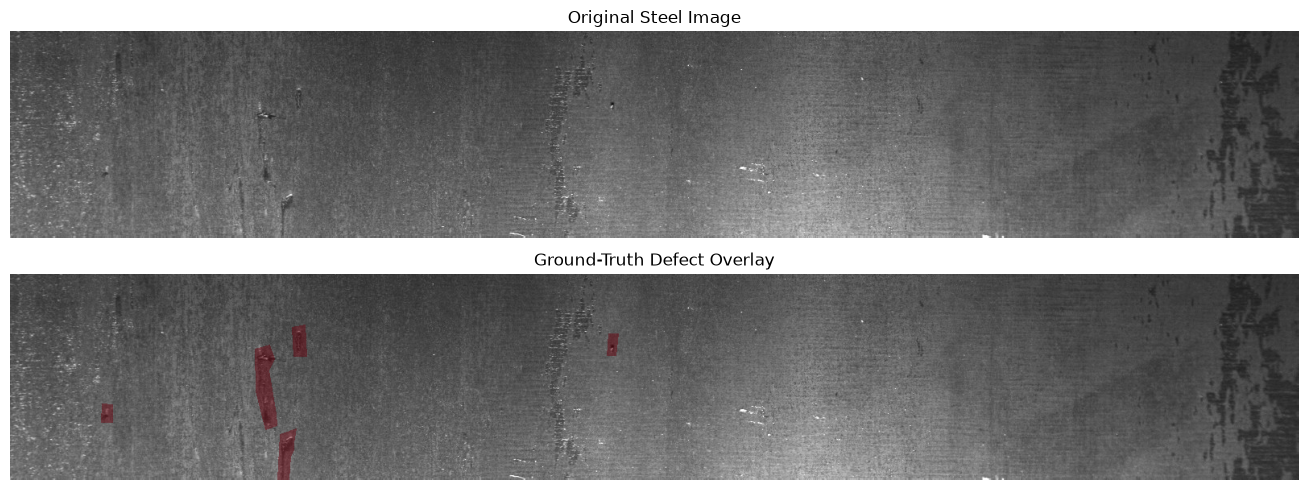

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Find an image containing a defect
idx = next(
    i for i, path in enumerate(highres_dataset.image_paths)
    if path.name in highres_dataset.annotations
    and highres_dataset.annotations[path.name]["EncodedPixels"].notna().any()
)

image, mask = highres_dataset[idx]

# Undo ImageNet normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image = (image.cpu() * std + mean).clamp(0, 1)
image = image.permute(1, 2, 0).numpy()
mask = mask.squeeze(0).cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(16, 5))

axes[0].imshow(image)
axes[0].set_title("Original Steel Image")

axes[1].imshow(image)
axes[1].imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="Reds",
    alpha=0.5,
    vmin=0,
    vmax=1
)
axes[1].set_title("Ground-Truth Defect Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
SEED = 42

indices = np.arange(len(lowres_dataset))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

# Low-resolution datasets
lowres_train = Subset(lowres_dataset, train_idx)
lowres_val = Subset(lowres_dataset, val_idx)

# High-resolution datasets
highres_train = Subset(highres_dataset, train_idx)
highres_val = Subset(highres_dataset, val_idx)

# DataLoaders
lowres_train_loader = DataLoader(
    lowres_train, batch_size=8, shuffle=True
)

lowres_val_loader = DataLoader(
    lowres_val, batch_size=8, shuffle=False
)

highres_train_loader = DataLoader(
    highres_train, batch_size=2, shuffle=True
)

highres_val_loader = DataLoader(
    highres_val, batch_size=2, shuffle=False
)

print(f"Training images: {len(train_idx)}")
print(f"Validation images: {len(val_idx)}")

Training images: 10054
Validation images: 2514


In [18]:
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    denominator = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (denominator + smooth)

    return 1 - dice.mean()


def segmentation_loss(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    dice = dice_loss(logits, targets)

    return bce + dice


def segmentation_metrics(logits, targets, threshold=0.5):
    predictions = (torch.sigmoid(logits) >= threshold).bool()
    targets = targets.bool()

    tp = (predictions & targets).sum().item()
    fp = (predictions & ~targets).sum().item()
    fn = (~predictions & targets).sum().item()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    dice = 2 * tp / (2 * tp + fp + fn + 1e-8)

    return {
        "precision": precision,
        "recall": recall,
        "dice": dice
    }

In [19]:
lowres_model.eval()

images, masks = next(iter(lowres_val_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = lowres_model(images)

loss = segmentation_loss(logits, masks)
metrics = segmentation_metrics(logits, masks)

print("Loss:", loss.item())
print("Metrics:", metrics)

Loss: 1.628488302230835
Metrics: {'precision': 0.004981906795861349, 'recall': 0.07505672892297954, 'dice': 0.009343628225000023}


In [20]:
from torch.optim import AdamW

optimizer = AdamW(
    lowres_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        logits = model(images)
        loss = segmentation_loss(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)

In [21]:
@torch.no_grad()
def validate_epoch(model, loader):
    model.eval()

    total_loss = 0.0
    tp = fp = fn = 0

    for images, masks in loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)
        loss = segmentation_loss(logits, masks)

        total_loss += loss.item() * images.size(0)

        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks.bool()

        tp += (predictions & targets).sum().item()
        fp += (predictions & ~targets).sum().item()
        fn += (~predictions & targets).sum().item()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    dice = 2 * tp / (2 * tp + fp + fn + 1e-8)

    return {
        "loss": total_loss / len(loader.dataset),
        "precision": precision,
        "recall": recall,
        "dice": dice
    }

In [22]:
EPOCHS = 10

history = []

best_dice = -1.0

for epoch in range(EPOCHS):
    train_loss = train_epoch(
        lowres_model,
        lowres_train_loader,
        optimizer
    )

    metrics = validate_epoch(
        lowres_model,
        lowres_val_loader
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **metrics
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {metrics['loss']:.4f} | "
        f"Precision: {metrics['precision']:.4f} | "
        f"Recall: {metrics['recall']:.4f} | "
        f"Dice: {metrics['dice']:.4f}"
    )

    if metrics["dice"] > best_dice:
        best_dice = metrics["dice"]

        torch.save(
            lowres_model.state_dict(),
            "lowres_best.pth"
        )

Epoch 1/10 | Train Loss: 0.8718 | Val Loss: 0.7424 | Precision: 0.6388 | Recall: 0.6845 | Dice: 0.6609
Epoch 2/10 | Train Loss: 0.7213 | Val Loss: 0.8879 | Precision: 0.6649 | Recall: 0.2417 | Dice: 0.3545
Epoch 3/10 | Train Loss: 0.6307 | Val Loss: 0.4953 | Precision: 0.5767 | Recall: 0.6418 | Dice: 0.6075
Epoch 4/10 | Train Loss: 0.6045 | Val Loss: 0.5283 | Precision: 0.5501 | Recall: 0.6011 | Dice: 0.5745
Epoch 5/10 | Train Loss: 0.5267 | Val Loss: 0.4385 | Precision: 0.6917 | Recall: 0.5709 | Dice: 0.6255
Epoch 6/10 | Train Loss: 0.5279 | Val Loss: 0.6664 | Precision: 0.3961 | Recall: 0.6490 | Dice: 0.4919
Epoch 7/10 | Train Loss: 0.5415 | Val Loss: 0.4283 | Precision: 0.6795 | Recall: 0.6029 | Dice: 0.6390
Epoch 8/10 | Train Loss: 0.4925 | Val Loss: 0.4073 | Precision: 0.6959 | Recall: 0.6089 | Dice: 0.6495
Epoch 9/10 | Train Loss: 0.4928 | Val Loss: 0.4330 | Precision: 0.6832 | Recall: 0.5783 | Dice: 0.6264
Epoch 10/10 | Train Loss: 0.4793 | Val Loss: 0.4604 | Precision: 0.7078 |

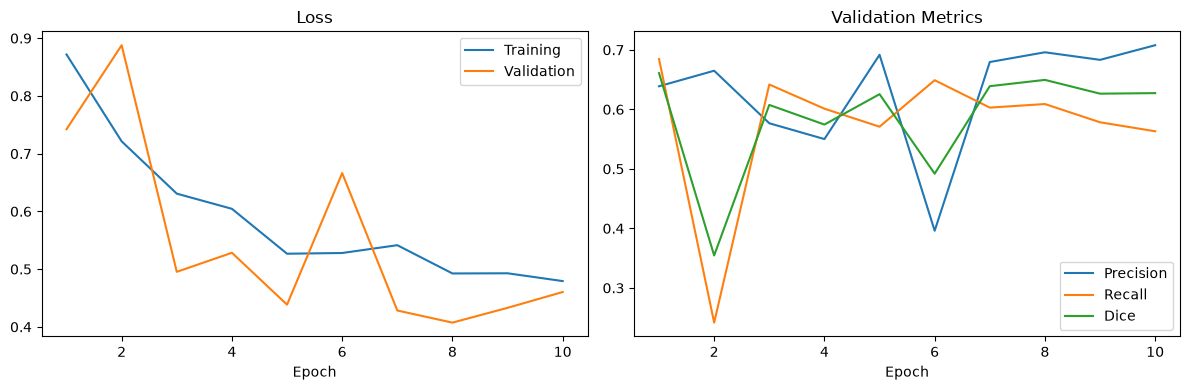

In [23]:
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Training")
axes[0].plot(history_df["epoch"], history_df["loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["precision"], label="Precision")
axes[1].plot(history_df["epoch"], history_df["recall"], label="Recall")
axes[1].plot(history_df["epoch"], history_df["dice"], label="Dice")
axes[1].set_title("Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [24]:
lowres_model.load_state_dict(
    torch.load(
        "lowres_best.pth",
        map_location=DEVICE,
        weights_only=True
    )
)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    tp = fp = fn = 0

    lowres_model.eval()

    with torch.no_grad():
        for images, masks in lowres_val_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            logits = lowres_model(images)
            predictions = torch.sigmoid(logits) >= threshold
            targets = masks.bool()

            tp += (predictions & targets).sum().item()
            fp += (predictions & ~targets).sum().item()
            fn += (~predictions & targets).sum().item()

    results.append({
        "threshold": threshold,
        "precision": tp / (tp + fp + 1e-8),
        "recall": tp / (tp + fn + 1e-8),
        "dice": 2 * tp / (2 * tp + fp + fn + 1e-8)
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)

,threshold,precision,recall,dice
0,0.1,0.427046,0.825183,0.562822
1,0.2,0.508587,0.773443,0.613656
2,0.3,0.567298,0.738630,0.641725
3,0.4,0.607164,0.710475,0.654770
4,0.5,0.638813,0.684525,0.660879
5,0.6,0.667604,0.657665,0.662597
6,0.7,0.699027,0.625012,0.659950


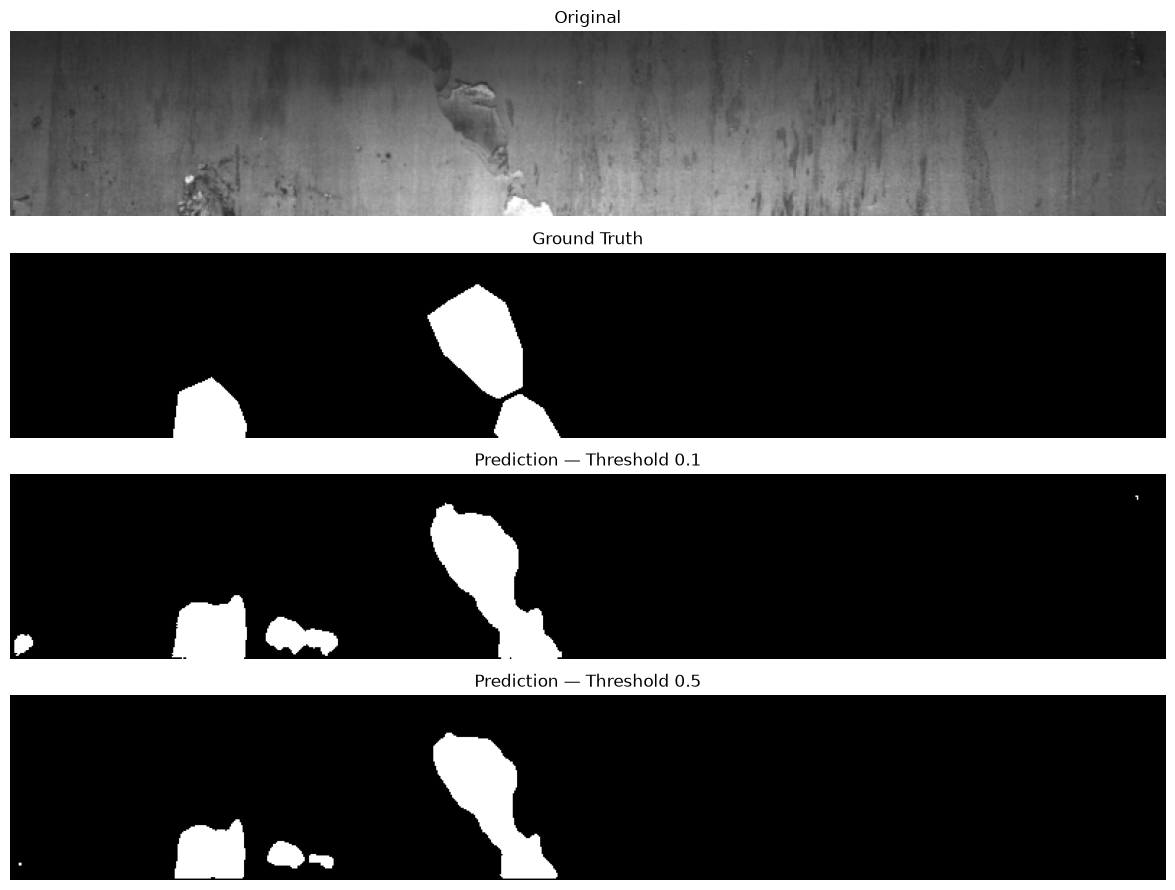

In [25]:
lowres_model.eval()

images, masks = next(iter(lowres_val_loader))

with torch.no_grad():
    logits = lowres_model(images.to(DEVICE))
    probabilities = torch.sigmoid(logits).cpu()

fig, axes = plt.subplots(4, 1, figsize=(16, 9))

image = images[0].cpu()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

image = (image * std + mean).clamp(0, 1)
image = image.permute(1, 2, 0).numpy()

axes[0].imshow(image)
axes[0].set_title("Original")

axes[1].imshow(masks[0, 0].numpy(), cmap="gray")
axes[1].set_title("Ground Truth")

for ax, threshold in zip(axes[2:], [0.1, 0.5]):
    prediction = probabilities[0, 0] >= threshold
    ax.imshow(prediction.numpy(), cmap="gray")
    ax.set_title(f"Prediction — Threshold {threshold}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

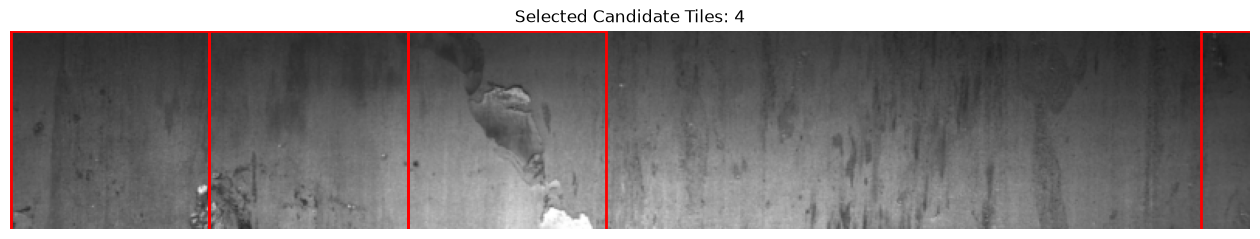

Selected tiles: 4/7
Tile selection rate: 57.14%


In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

threshold = 0.1
tile_size = 128

probability = probabilities[0, 0].numpy()
selected_tiles = []

height, width = probability.shape

fig, ax = plt.subplots(figsize=(16, 4))
ax.imshow(image)

for y in range(0, height, tile_size):
    for x in range(0, width, tile_size):
        tile = probability[y:y+tile_size, x:x+tile_size]

        if (tile >= threshold).any():
            selected_tiles.append((x, y))

            rect = patches.Rectangle(
                (x, y),
                min(tile_size, width - x),
                min(tile_size, height - y),
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)

ax.set_title(f"Selected Candidate Tiles: {len(selected_tiles)}")
ax.axis("off")
plt.show()

total_tiles = (
    ((height + tile_size - 1) // tile_size)
    * ((width + tile_size - 1) // tile_size)
)

print(f"Selected tiles: {len(selected_tiles)}/{total_tiles}")
print(f"Tile selection rate: {len(selected_tiles)/total_tiles:.2%}")

In [28]:
lowres_model.eval()

images, masks = next(iter(lowres_val_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    logits = lowres_model(images)

loss = segmentation_loss(logits, masks)
metrics = segmentation_metrics(logits, masks)

print("Loss:", loss.item())
print("Metrics:", metrics)

Loss: 0.7571089267730713
Metrics: {'precision': 0.28243981091277026, 'recall': 0.896898818874209, 'dice': 0.4295966000138745}
